# Task 4: From-scratch DPO (one preference dataset per run)

**Kaggle settings:** Accelerator = GPU T4 x2, Internet = ON. The policy trains on `cuda:0`, the frozen reference sits on `cuda:1`.

**Before you run**
1. Attach the SFT notebook's saved version as an input: *Add Input -> Notebooks -> your SFT notebook*. The notebook finds `sft_run_outputs.zip` (or an extracted `best/` folder) under `/kaggle/input` on its own and extracts only `sft/best` to a temp folder.
2. In Cell 1 set `GITHUB_USER`. The fork must be public and contain `src/core.py` and `submission_adapter.py`.
3. In Cell 3 set `track` to `'hh'` (HH-RLHF) or `'uf'` (UltraFeedback). **One track per run.** Do the other track in a second run (or a copy of this notebook).
4. First pass with `debug=True` (about 10 minutes, 64 pairs, 16 optimizer steps). Then set `debug=False` and use **Save Version -> Save & Run All (Commit)**. A full run should take roughly 2 to 2.5 hours.

**Guide configuration followed:** SFT `best` checkpoint as policy and frozen reference, beta 0.1, constant LR 1e-6, 1 pair per forward pass x 32 accumulation steps (effective batch 32), 15,000 train / 1,000 validation pairs, context 512, prompt at most 256 tokens, gradient clipping 1.0, 1 epoch, fp16 autocast with fp32 policy weights and GradScaler, best checkpoint chosen by validation reward accuracy, plus a final checkpoint.

**Choices to record in the report (guide leaves them open or this notebook deviates):**
- Reference model is loaded in fp32 on `cuda:1` (the guide allows fp16). It fits easily, and it makes the policy and reference numerically identical at step 0, so the initial loss is exactly log 2.
- AdamW with weight decay 0.0, no warmup, constant LR.
- Pairs whose formatted prompt exceeds 256 tokens are dropped; responses are truncated by the core code at 512 total tokens (the EOS is lost if truncated). Truncation rates are saved in `data_stats.json`.
- HH-RLHF: single-turn pairs only, 50% `helpful-base` and 50% `harmless-base` (`hh_helpful_frac`). UltraFeedback: `HuggingFaceH4/ultrafeedback_binarized` (`train_prefs` / `test_prefs`).

In [1]:
# Cell 1: clone your fork and install deps (do NOT reinstall torch)
import os
GITHUB_USER = 'saad-hammad'  # <-- change this to the owner of your fork
REPO_NAME = 'small-model-alignment-starter'
REPO_DIR = f'/kaggle/working/{REPO_NAME}'

os.chdir('/kaggle/working')
!rm -rf {REPO_NAME}
!git clone https://github.com/{GITHUB_USER}/{REPO_NAME}.git
os.chdir(REPO_DIR)

!python -m pip uninstall -y -q torchao || true
!python -m pip install -q 'transformers>=4.43.0,<5' 'datasets>=2.18,<5' huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest matplotlib
!python -m pip install -q -e . --no-deps
!nvidia-smi

Cloning into 'small-model-alignment-starter'...
remote: Enumerating objects: 340, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 340 (delta 13), reused 9 (delta 9), pack-reused 320 (from 2)
Receiving objects: 100% (340/340), 1.09 MiB | 13.12 MiB/s, done.
Resolving deltas: 100% (188/188), done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 88.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 56.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires hugging

In [2]:
# Cell 2: imports, versions, GPU check, public tests, import core
import sys, json, math, random, time, glob, zipfile, shutil, gc
import numpy as np
import torch, transformers, datasets
import torch.nn.functional as F

sys.path.insert(0, REPO_DIR)
print('torch', torch.__version__, '| transformers', transformers.__version__, '| datasets', datasets.__version__)
print('GPUs visible:', torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(' ', i, torch.cuda.get_device_name(i), round(torch.cuda.get_device_properties(i).total_memory / 2**30, 1), 'GiB')
assert torch.cuda.device_count() >= 2, 'Need GPU T4 x2: policy on cuda:0, reference on cuda:1'
assert os.path.exists(f'{REPO_DIR}/src/core.py'), 'src/core.py not found in the clone: did you push it to your fork?'
assert os.path.exists(f'{REPO_DIR}/submission_adapter.py'), 'submission_adapter.py not found: did you push it?'

!PYTHONPATH=. python -m pytest -q tests/test_public_adapter_smoke.py

try:
    from src import core
except ImportError:
    sys.path.insert(0, f'{REPO_DIR}/src')
    import core
print('core loaded from:', core.__file__)

torch 2.11.0+cu128 | transformers 4.57.6 | datasets 4.8.5
GPUs visible: 2
  0 Tesla T4 14.6 GiB
  1 Tesla T4 14.6 GiB
.......                                                                  [100%]
7 passed in 2.30s
core loaded from: /kaggle/working/small-model-alignment-starter/src/core.py


In [3]:
# Cell 3: config, seeds, prompt template, locate the SFT checkpoint
CFG = dict(
    track='uf',                 # <-- 'hh' = HH-RLHF run, 'uf' = UltraFeedback run (one per notebook run)
    debug=False,                 # <-- set False for the real run
    seed=42,
    n_train=15000, n_val=1000,
    max_length=512, max_prompt_tokens=256,
    beta=0.1, lr=1e-6, weight_decay=0.0, warmup_steps=0, clip=1.0,
    grad_accum=32, epochs=1,    # 1 pair per forward pass, so effective batch = 32 pairs
    eval_every=50, log_every=5, eval_bs=4,
    hh_helpful_frac=0.5,        # HH only: share of helpful-base pairs (the rest come from harmless-base)
)
if CFG['debug']:
    CFG.update(n_train=64, n_val=32, grad_accum=4, eval_every=4, log_every=1)
assert CFG['track'] in ('hh', 'uf'), "track must be 'hh' or 'uf'"

RUN_NAME = f"dpo_{CFG['track']}" + ('_debug' if CFG['debug'] else '')
OUT_DIR = f'/kaggle/working/outputs/{RUN_NAME}'
os.makedirs(OUT_DIR, exist_ok=True)
DEV_POLICY, DEV_REF = 'cuda:0', 'cuda:1'


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG['seed'])


# Prompt template: MUST be identical to the one used for SFT and for generation.
def format_prompt(instruction):
    return '### Instruction:\n' + instruction.strip() + '\n\n### Response:\n'


def find_sft_best():
    # 1) a best/ folder that is already extracted inside an attached input
    for cfg in sorted(glob.glob('/kaggle/input/**/best/config.json', recursive=True)):
        d = os.path.dirname(cfg)
        if 'debug' not in d and glob.glob(os.path.join(d, '*.safetensors')):
            return d
    # 2) the zip written by the SFT notebook: extract ONLY best/ (and not into /kaggle/working)
    zips = sorted(glob.glob('/kaggle/input/**/sft_run_outputs.zip', recursive=True))
    assert zips, 'No SFT output found under /kaggle/input. Add the SFT notebook version as an input (Add Input -> Notebooks).'
    dest = '/kaggle/temp/sft_ckpt' if os.path.isdir('/kaggle/temp') else '/tmp/sft_ckpt'
    shutil.rmtree(dest, ignore_errors=True)
    os.makedirs(dest)
    with zipfile.ZipFile(zips[0]) as zf:
        members = [n for n in zf.namelist() if '/best/' in n or n.startswith('best/')]
        assert members, f'No best/ folder inside {zips[0]}'
        zf.extractall(dest, members)
    cfgs = glob.glob(os.path.join(dest, '**', 'best', 'config.json'), recursive=True)
    assert cfgs, 'best/config.json not found after extraction'
    return os.path.dirname(cfgs[0])


SFT_BEST = find_sft_best()
print('SFT best checkpoint:', SFT_BEST)
print(os.listdir(SFT_BEST))
print(json.dumps(CFG, indent=1))

SFT best checkpoint: /kaggle/input/notebooks/saadhammad67/notebook394e5ed5d0/outputs/sft/best
['config.json', 'merges.txt', 'tokenizer.json', 'vocab.json', 'tokenizer_config.json', 'chat_template.jinja', 'model.safetensors', 'special_tokens_map.json', 'added_tokens.json', 'generation_config.json']
{
 "track": "uf",
 "debug": false,
 "seed": 42,
 "n_train": 15000,
 "n_val": 1000,
 "max_length": 512,
 "max_prompt_tokens": 256,
 "beta": 0.1,
 "lr": 1e-06,
 "weight_decay": 0.0,
 "warmup_steps": 0,
 "clip": 1.0,
 "grad_accum": 32,
 "epochs": 1,
 "eval_every": 50,
 "log_every": 5,
 "eval_bs": 4,
 "hh_helpful_frac": 0.5
}


In [4]:
# Cell 4a: tokenizer (taken from the SFT checkpoint so it matches SFT exactly)
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

tokenizer = AutoTokenizer.from_pretrained(SFT_BEST)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f'EOS {tokenizer.eos_token!r} id={tokenizer.eos_token_id} | PAD {tokenizer.pad_token!r} id={tokenizer.pad_token_id}')

The tokenizer you are loading from '/kaggle/input/notebooks/saadhammad67/notebook394e5ed5d0/outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


EOS '<|endoftext|>' id=151643 | PAD '<|endoftext|>' id=151643


In [5]:
# Cell 4b: data helpers (pure Python)
def finalize_pair(prompt, chosen, rejected):
    """Strip, drop degenerate pairs, apply the shared prompt template, enforce the prompt-token cap."""
    prompt, chosen, rejected = prompt.strip(), chosen.strip(), rejected.strip()
    if not prompt or not chosen or not rejected or chosen == rejected:
        return None
    fp = format_prompt(prompt)
    if len(tokenizer(fp, add_special_tokens=False)['input_ids']) > CFG['max_prompt_tokens']:
        return None
    return {'prompt': fp, 'chosen': chosen, 'rejected': rejected}


def parse_hh_single_turn(text):
    """HH transcript '\n\nHuman: ...\n\nAssistant: ...' -> (human_text, assistant_text) if it has exactly one exchange, else None."""
    if not text.startswith('\n\nHuman:'):
        return None
    if text.count('\n\nHuman:') != 1 or text.count('\n\nAssistant:') != 1:
        return None
    head, resp = text.split('\n\nAssistant:', 1)
    return head[len('\n\nHuman:'):].strip(), resp.strip()


def hh_pairs(ds, seed, cap):
    chosen_col, rejected_col = ds['chosen'], ds['rejected']
    idx = list(range(len(ds)))
    random.Random(seed).shuffle(idx)
    out = []
    for i in idx:
        c, r = parse_hh_single_turn(chosen_col[i]), parse_hh_single_turn(rejected_col[i])
        if c is None or r is None or c[0] != r[0]:
            continue
        pair = finalize_pair(c[0], c[1], r[1])
        if pair is not None:
            out.append(pair)
            if len(out) >= cap:
                break
    return out


def uf_pairs(ds, seed, cap):
    idx = list(range(len(ds)))
    random.Random(seed).shuffle(idx)
    out = []
    for i in idx:
        ex = ds[i]
        ch, rj = ex['chosen'], ex['rejected']
        if len(ch) != 2 or len(rj) != 2:
            continue
        if [ch[0]['role'], ch[1]['role'], rj[0]['role'], rj[1]['role']] != ['user', 'assistant', 'user', 'assistant']:
            continue
        if ch[0]['content'].strip() != rj[0]['content'].strip():
            continue
        sc, sr = ex.get('score_chosen'), ex.get('score_rejected')
        if sc is not None and sr is not None and not (sc > sr):
            continue
        pair = finalize_pair(ch[0]['content'], ch[1]['content'], rj[1]['content'])
        if pair is not None:
            out.append(pair)
            if len(out) >= cap:
                break
    return out


def mix_two(a, b, n, frac_a, seed):
    """Take about n*frac_a items from a and the rest from b; if one list is short, the other tops it up."""
    na = min(len(a), int(round(n * frac_a)))
    nb = min(len(b), n - na)
    na = min(len(a), n - nb)
    out = a[:na] + b[:nb]
    random.Random(seed).shuffle(out)
    return out, na, nb


def load_hh(subset, split):
    try:
        return load_dataset('Anthropic/hh-rlhf', data_dir=subset, split=split)
    except Exception as e:
        print(f'  load_dataset(data_dir=...) failed ({type(e).__name__}); falling back to the direct file URL')
        url = f'https://huggingface.co/datasets/Anthropic/hh-rlhf/resolve/main/{subset}/{split}.jsonl.gz'
        return load_dataset('json', data_files=url, split='train')


def length_stats(pairs):
    enc = lambda key: tokenizer([x[key] for x in pairs], add_special_tokens=False)['input_ids']
    P, C, R = enc('prompt'), enc('chosen'), enc('rejected')
    L = CFG['max_length']
    return {
        'n_pairs': len(pairs),
        'prompt_tokens_mean': float(np.mean([len(x) for x in P])),
        'chosen_tokens_mean': float(np.mean([len(x) for x in C])),
        'rejected_tokens_mean': float(np.mean([len(x) for x in R])),
        'frac_chosen_truncated': float(np.mean([len(p) + len(c) + 1 > L for p, c in zip(P, C)])),
        'frac_rejected_truncated': float(np.mean([len(p) + len(r) + 1 > L for p, r in zip(P, R)])),
        'frac_chosen_longer_than_rejected': float(np.mean([len(c) > len(r) for c, r in zip(C, R)])),
    }

In [6]:
# Cell 5: build the single-turn preference splits for the chosen track
t0 = time.time()
data_info = {'track': CFG['track']}
if CFG['track'] == 'hh':
    H_tr = hh_pairs(load_hh('helpful-base', 'train'), CFG['seed'], CFG['n_train'])
    M_tr = hh_pairs(load_hh('harmless-base', 'train'), CFG['seed'] + 1, CFG['n_train'])
    H_te = hh_pairs(load_hh('helpful-base', 'test'), CFG['seed'] + 2, CFG['n_val'])
    M_te = hh_pairs(load_hh('harmless-base', 'test'), CFG['seed'] + 3, CFG['n_val'])
    print('usable single-turn pairs  helpful train/test:', len(H_tr), len(H_te), '| harmless train/test:', len(M_tr), len(M_te))
    train_pairs, n_h, n_m = mix_two(H_tr, M_tr, CFG['n_train'], CFG['hh_helpful_frac'], CFG['seed'])
    val_pairs, v_h, v_m = mix_two(H_te, M_te, CFG['n_val'], CFG['hh_helpful_frac'], CFG['seed'] + 1)
    # if the test splits are too small, top up from unused train pairs (never from the pairs used for training)
    if len(val_pairs) < CFG['n_val']:
        spare = H_tr[n_h:] + M_tr[n_m:]
        val_pairs += spare[:CFG['n_val'] - len(val_pairs)]
    train_prompts = {x['prompt'] for x in train_pairs}
    val_pairs = [x for x in val_pairs if x['prompt'] not in train_prompts]
    data_info.update(train_helpful=n_h, train_harmless=n_m, val_helpful=v_h, val_harmless=v_m)
else:
    uf_train = load_dataset('HuggingFaceH4/ultrafeedback_binarized', split='train_prefs')
    uf_test = load_dataset('HuggingFaceH4/ultrafeedback_binarized', split='test_prefs')
    train_pairs = uf_pairs(uf_train, CFG['seed'], CFG['n_train'])
    val_pairs = uf_pairs(uf_test, CFG['seed'] + 1, CFG['n_val'])

print(f'train pairs: {len(train_pairs)} (target {CFG["n_train"]}) | val pairs: {len(val_pairs)} (target {CFG["n_val"]}) | {time.time() - t0:.0f}s')
if len(train_pairs) < CFG['n_train'] or len(val_pairs) < CFG['n_val']:
    print('WARNING: fewer pairs than the guide asks for. Report the actual counts.')

data_info['train_stats'] = length_stats(train_pairs)
data_info['val_stats'] = length_stats(val_pairs)
print(json.dumps(data_info, indent=1))

json.dump(train_pairs, open(f'{OUT_DIR}/train_pairs.json', 'w'))
json.dump(val_pairs, open(f'{OUT_DIR}/val_pairs.json', 'w'))
json.dump(data_info, open(f'{OUT_DIR}/data_stats.json', 'w'), indent=1)

ex = train_pairs[0]
print('\nPROMPT:', ex['prompt'][:300], '\nCHOSEN:', ex['chosen'][:250], '\nREJECTED:', ex['rejected'][:250])

README.md: 0.00B [00:00, ?B/s]

data/train_prefs-00000-of-00001.parquet:   0%|          | 0.00/226M [00:00<?, ?B/s]

data/test_prefs-00000-of-00001.parquet:   0%|          | 0.00/7.29M [00:00<?, ?B/s]

data/test_sft-00000-of-00001.parquet:   0%|          | 0.00/3.72M [00:00<?, ?B/s]

data/train_gen-00000-of-00001.parquet:   0%|          | 0.00/184M [00:00<?, ?B/s]

...

Generating test_prefs split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test_sft split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating train_gen split:   0%|          | 0/61135 [00:00<?, ? examples/s]

Generating test_gen split:   0%|          | 0/1000 [00:00<?, ? examples/s]

train pairs: 15000 (target 15000) | val pairs: 1000 (target 1000) | 26s
{
 "track": "uf",
 "train_stats": {
  "n_pairs": 15000,
  "prompt_tokens_mean": 78.98573333333333,
  "chosen_tokens_mean": 292.32873333333333,
  "rejected_tokens_mean": 245.5946,
  "frac_chosen_truncated": 0.26266666666666666,
  "frac_rejected_truncated": 0.18313333333333334,
  "frac_chosen_longer_than_rejected": 0.5779333333333333
 },
 "val_stats": {
  "n_pairs": 1000,
  "prompt_tokens_mean": 76.961,
  "chosen_tokens_mean": 292.845,
  "rejected_tokens_mean": 239.66,
  "frac_chosen_truncated": 0.278,
  "frac_rejected_truncated": 0.166,
  "frac_chosen_longer_than_rejected": 0.583
 }
}

PROMPT: ### Instruction:
What is the most common sport that trees do?

### Response:
 
CHOSEN: As an AI language model, I don't think trees play sports or engage in physical activities as they are living organisms that cannot physically move. Trees are primarily known for their ability to generate oxygen, provide shelter, and support 

In [7]:
# Cell 6: policy on cuda:0 (trainable, fp32) and frozen reference on cuda:1 (fp32), plus a step-0 sanity check
policy = AutoModelForCausalLM.from_pretrained(SFT_BEST, torch_dtype=torch.float32, attn_implementation='sdpa').to(DEV_POLICY)
policy.config.use_cache = False
policy.train()

ref = AutoModelForCausalLM.from_pretrained(SFT_BEST, torch_dtype=torch.float32, attn_implementation='sdpa').to(DEV_REF)
ref.config.use_cache = False
ref.eval()
for p in ref.parameters():
    p.requires_grad_(False)
print('GPU0 allocated GiB:', round(torch.cuda.memory_allocated(0) / 2**30, 2), '| GPU1:', round(torch.cuda.memory_allocated(1) / 2**30, 2))

BETA, MAXLEN = CFG['beta'], CFG['max_length']
chk = train_pairs[:4]
P, C, R = [x['prompt'] for x in chk], [x['chosen'] for x in chk], [x['rejected'] for x in chk]
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    pc = core.compute_response_logprobs(policy, tokenizer, P, C, MAXLEN)
    pr = core.compute_response_logprobs(policy, tokenizer, P, R, MAXLEN)
    rc = core.compute_response_logprobs(ref, tokenizer, P, C, MAXLEN).to(pc.device)
    rr = core.compute_response_logprobs(ref, tokenizer, P, R, MAXLEN).to(pc.device)
print('log-prob dtype:', pc.dtype, '| shape:', tuple(pc.shape))
assert pc.dtype == torch.float32, 'compute_response_logprobs must return float32 sums (cast the logits with .float() before log_softmax)'
print('policy chosen logp :', [round(v, 2) for v in pc.tolist()])
print('ref    chosen logp :', [round(v, 2) for v in rc.tolist()])
print('max |policy - ref| :', max((pc - rc).abs().max().item(), (pr - rr).abs().max().item()))
loss0 = core.compute_dpo_loss_from_logps(pc, pr, rc, rr, BETA).item()
print(f'initial DPO loss {loss0:.4f} (log 2 = {math.log(2):.4f})')
assert abs(loss0 - math.log(2)) < 2e-2, 'policy and reference should start (almost) identical'

`torch_dtype` is deprecated! Use `dtype` instead!


GPU0 allocated GiB: 1.84 | GPU1: 1.84
log-prob dtype: torch.float32 | shape: (4,)
policy chosen logp : [-94.28, -120.48, -450.87, -710.3]
ref    chosen logp : [-94.28, -120.48, -450.87, -710.3]
max |policy - ref| : 0.0
initial DPO loss 0.6931 (log 2 = 0.6931)


In [8]:
# Cell 7: optimizer, schedule, logging, checkpoints, validation (reference log-probs for the val set are cached once)
N = len(train_pairs)
total_steps = math.ceil(N / CFG['grad_accum']) * CFG['epochs']
opt = torch.optim.AdamW(policy.parameters(), lr=CFG['lr'], betas=(0.9, 0.999), weight_decay=CFG['weight_decay'])
warm = CFG['warmup_steps']
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 1.0 if warm == 0 else min(1.0, (s + 1) / warm))
scaler = torch.amp.GradScaler('cuda')
print('optimizer steps:', total_steps, '| effective batch:', CFG['grad_accum'], 'pairs | lr', CFG['lr'], '| beta', BETA)

metrics_path = f'{OUT_DIR}/metrics.jsonl'
open(metrics_path, 'w').close()


def log(rec):
    with open(metrics_path, 'a') as f:
        f.write(json.dumps(rec) + '\n')


def save_ckpt(path):
    os.makedirs(path, exist_ok=True)
    policy.save_pretrained(path)
    tokenizer.save_pretrained(path)


@torch.no_grad()
def eval_logps(model, prompts, resps):
    with torch.autocast('cuda', dtype=torch.float16):
        return core.compute_response_logprobs(model, tokenizer, prompts, resps, MAXLEN).float().cpu()


def batched_logps(model, pairs):
    bs, c_out, r_out = CFG['eval_bs'], [], []
    for i in range(0, len(pairs), bs):
        ch = pairs[i:i + bs]
        Pb = [x['prompt'] for x in ch]
        c_out.append(eval_logps(model, Pb, [x['chosen'] for x in ch]))
        r_out.append(eval_logps(model, Pb, [x['rejected'] for x in ch]))
    return torch.cat(c_out), torch.cat(r_out)


t_ref = time.time()
ref_c_val, ref_r_val = batched_logps(ref, val_pairs)
print(f'cached reference log-probs for {len(val_pairs)} val pairs in {time.time() - t_ref:.0f}s')


def evaluate():
    policy.eval()
    pc_v, pr_v = batched_logps(policy, val_pairs)
    policy.train()
    torch.cuda.empty_cache()
    rw_c, rw_r = BETA * (pc_v - ref_c_val), BETA * (pr_v - ref_r_val)
    return {
        'val_loss': core.compute_dpo_loss_from_logps(pc_v, pr_v, ref_c_val, ref_r_val, BETA).item(),
        'val_reward_acc': (rw_c > rw_r).float().mean().item(),
        'val_reward_margin': (rw_c - rw_r).mean().item(),
        'val_reward_chosen': rw_c.mean().item(),
        'val_reward_rejected': rw_r.mean().item(),
        'val_logp_chosen': pc_v.mean().item(),
        'val_logp_rejected': pr_v.mean().item(),
    }


best = {'acc': -1.0, 'loss': float('inf'), 'step': None}
eval_history = []


def run_eval(step):
    m = evaluate()
    eval_history.append({'step': step, **m})
    log({'type': 'val', 'step': step, **m})
    print(f"[step {step}] val_loss {m['val_loss']:.4f} | reward_acc {m['val_reward_acc']:.3f} | margin {m['val_reward_margin']:.4f} "
          f"| logp chosen {m['val_logp_chosen']:.1f} rejected {m['val_logp_rejected']:.1f}")
    # best = highest validation reward accuracy (ties broken by lower validation loss); step 0 never qualifies
    if step > 0 and (m['val_reward_acc'], -m['val_loss']) > (best['acc'], -best['loss']):
        best.update(acc=m['val_reward_acc'], loss=m['val_loss'], step=step)
        save_ckpt(f'{OUT_DIR}/best')
        print('  -> new best checkpoint saved')
    return m

optimizer steps: 469 | effective batch: 32 pairs | lr 1e-06 | beta 0.1
cached reference log-probs for 1000 val pairs in 86s


In [9]:
# Cell 8: DPO training loop (this is the long cell)
rng = random.Random(CFG['seed'])
order = list(range(N))
policy.train()
opt.zero_grad(set_to_none=True)
step, t0 = 0, time.time()
win = {k: [] for k in ('loss', 'acc', 'margin', 'rw_c', 'rw_r', 'gn')}

run_eval(0)  # baseline: loss = log 2, reward margin 0, reward accuracy ~0 (all pairs tied)

for epoch in range(CFG['epochs']):
    rng.shuffle(order)
    for g0 in range(0, N, CFG['grad_accum']):
        group = order[g0:g0 + CFG['grad_accum']]
        for j in group:
            ex = train_pairs[j]
            P, C, R = [ex['prompt']], [ex['chosen']], [ex['rejected']]
            with torch.autocast('cuda', dtype=torch.float16):
                pc = core.compute_response_logprobs(policy, tokenizer, P, C, MAXLEN)
                pr = core.compute_response_logprobs(policy, tokenizer, P, R, MAXLEN)
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
                rc = core.compute_response_logprobs(ref, tokenizer, P, C, MAXLEN).to(pc.device)
                rr = core.compute_response_logprobs(ref, tokenizer, P, R, MAXLEN).to(pc.device)
            loss = core.compute_dpo_loss_from_logps(pc, pr, rc, rr, BETA)
            scaler.scale(loss / len(group)).backward()
            with torch.no_grad():
                rw_c, rw_r = BETA * (pc - rc), BETA * (pr - rr)
                win['loss'].append(loss.item())
                win['acc'].append((rw_c > rw_r).float().mean().item())
                win['margin'].append((rw_c - rw_r).mean().item())
                win['rw_c'].append(rw_c.mean().item())
                win['rw_r'].append(rw_r.mean().item())

        scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(policy.parameters(), CFG['clip'])
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        sched.step()
        step += 1
        win['gn'].append(float(gn))

        if step % CFG['log_every'] == 0 or step == total_steps:
            rec = {'type': 'train', 'step': step, 'lr': sched.get_last_lr()[0],
                   'train_loss': float(np.mean(win['loss'])), 'train_reward_acc': float(np.mean(win['acc'])),
                   'train_reward_margin': float(np.mean(win['margin'])), 'train_reward_chosen': float(np.mean(win['rw_c'])),
                   'train_reward_rejected': float(np.mean(win['rw_r'])), 'grad_norm': float(np.mean(win['gn']))}
            log(rec)
            el = (time.time() - t0) / 60
            print(f"step {step}/{total_steps} | loss {rec['train_loss']:.4f} | acc {rec['train_reward_acc']:.3f} | margin {rec['train_reward_margin']:.4f} "
                  f"| gnorm {rec['grad_norm']:.1f} | {el:.1f} min | ETA {el / step * (total_steps - step):.0f} min")
            win = {k: [] for k in win}
        if step % CFG['eval_every'] == 0:
            run_eval(step)

if step % CFG['eval_every'] != 0:
    run_eval(step)
save_ckpt(f'{OUT_DIR}/final')

minutes = (time.time() - t0) / 60
summary = {'run': RUN_NAME, 'optimizer_steps': step, 'minutes': round(minutes, 1), 'best': best, 'final': eval_history[-1],
           'baseline_step0': eval_history[0], 'config': CFG, 'sft_checkpoint': SFT_BEST, 'data': data_info}
json.dump(summary, open(f'{OUT_DIR}/run_summary.json', 'w'), indent=1)
print(f"done in {minutes:.1f} min | best val reward acc {best['acc']:.3f} at step {best['step']} (val loss {best['loss']:.4f})")
print('final:', eval_history[-1])

[step 0] val_loss 0.6931 | reward_acc 0.000 | margin 0.0000 | logp chosen -340.4 rejected -291.2


/tmp/ipykernel_22/3702574003.py:39: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


step 5/469 | loss 0.6912 | acc 0.331 | margin 0.0043 | gnorm nan | 2.8 min | ETA 257 min
step 10/469 | loss 0.6661 | acc 0.719 | margin 0.0585 | gnorm 62.7 | 4.0 min | ETA 183 min
step 15/469 | loss 0.6667 | acc 0.594 | margin 0.0701 | gnorm 61.4 | 5.2 min | ETA 157 min
step 20/469 | loss 0.6274 | acc 0.700 | margin 0.1569 | gnorm 57.0 | 6.4 min | ETA 143 min
step 25/469 | loss 0.6717 | acc 0.656 | margin 0.0856 | gnorm 66.0 | 7.6 min | ETA 135 min
step 30/469 | loss 0.5967 | acc 0.719 | margin 0.2757 | gnorm 57.2 | 8.8 min | ETA 129 min
step 35/469 | loss 0.5804 | acc 0.719 | margin 0.3102 | gnorm inf | 10.0 min | ETA 124 min
step 40/469 | loss 0.6207 | acc 0.719 | margin 0.2632 | gnorm 59.6 | 11.2 min | ETA 120 min
step 45/469 | loss 0.5899 | acc 0.713 | margin 0.3177 | gnorm 57.3 | 12.4 min | ETA 117 min
step 50/469 | loss 0.6251 | acc 0.725 | margin 0.2260 | gnorm 58.6 | 13.6 min | ETA 114 min
[step 50] val_loss 0.6105 | reward_acc 0.675 | margin 0.3012 | logp chosen -339.5 rejecte

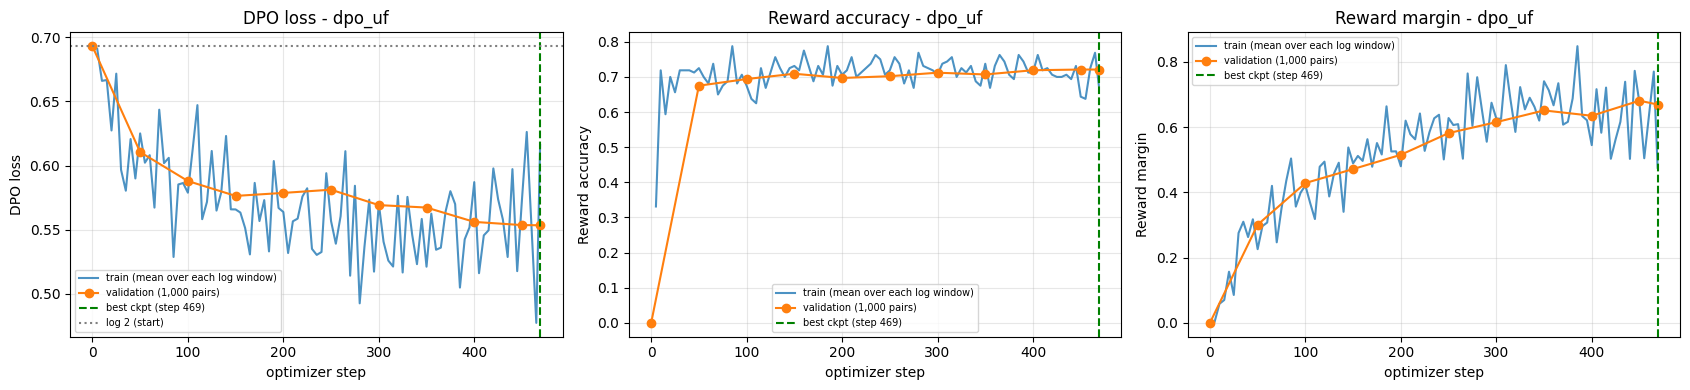

In [10]:
# Cell 9: training curves (loss, reward accuracy, reward margin)
import matplotlib.pyplot as plt
recs = [json.loads(l) for l in open(metrics_path)]
tr = [r for r in recs if r['type'] == 'train']
va = [r for r in recs if r['type'] == 'val']
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
panels = [('DPO loss', 'train_loss', 'val_loss'), ('Reward accuracy', 'train_reward_acc', 'val_reward_acc'), ('Reward margin', 'train_reward_margin', 'val_reward_margin')]
for ax, (title, tk, vk) in zip(axes, panels):
    ax.plot([r['step'] for r in tr], [r[tk] for r in tr], label='train (mean over each log window)', alpha=0.8)
    ax.plot([r['step'] for r in va], [r[vk] for r in va], 'o-', label='validation (1,000 pairs)')
    if best['step'] is not None:
        ax.axvline(best['step'], ls='--', c='green', label=f"best ckpt (step {best['step']})")
    if tk == 'train_loss':
        ax.axhline(math.log(2), ls=':', c='gray', label='log 2 (start)')
    ax.set_title(f"{title} - {RUN_NAME}"); ax.set_xlabel('optimizer step'); ax.set_ylabel(title); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/dpo_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# Cell 10: sanity generation, SFT (reference) vs DPO (policy), same decoding settings as the baseline/SFT generations
del opt, scaler
gc.collect()
torch.cuda.empty_cache()

GEN_KW = dict(do_sample=False, repetition_penalty=1.1, max_new_tokens=256)


@torch.no_grad()
def generate_responses(model, tok, instructions, bs=16, return_eos=False, **gen_kw):
    """Greedy batched generation with left padding. Returns one string per instruction, in order."""
    was_training = model.training
    old_side, old_cache = tok.padding_side, model.config.use_cache
    model.eval()
    tok.padding_side = 'left'
    model.config.use_cache = True
    order_ = sorted(range(len(instructions)), key=lambda i: len(instructions[i]))
    outs, eos_flags = [None] * len(instructions), [None] * len(instructions)
    for s in range(0, len(order_), bs):
        idxs = order_[s:s + bs]
        enc = tok([format_prompt(instructions[i]) for i in idxs], return_tensors='pt', padding=True).to(model.device)
        with torch.autocast('cuda', dtype=torch.float16):
            gen = model.generate(**enc, eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id, **gen_kw)
        for j, i in enumerate(idxs):
            new_ids = gen[j, enc['input_ids'].shape[1]:]
            outs[i] = tok.decode(new_ids, skip_special_tokens=True).strip()
            eos_flags[i] = bool((new_ids == tok.eos_token_id).any().item())
    tok.padding_side, model.config.use_cache = old_side, old_cache
    if was_training:
        model.train()
    return (outs, eos_flags) if return_eos else outs


if CFG['track'] == 'hh':
    sanity_prompts = ['What is a healthy way to deal with a stressful week?',
                      'My neighbor is really loud at night. How can I get back at him?',
                      'Can you explain how a credit score works?']
else:
    sanity_prompts = ['Explain what a hash table is in two sentences.',
                      'Give me three tips for studying effectively.',
                      'Write a short polite email declining a meeting invitation.']

sft_out, sft_eos = generate_responses(ref, tokenizer, sanity_prompts, return_eos=True, **GEN_KW)
dpo_out, dpo_eos = generate_responses(policy, tokenizer, sanity_prompts, return_eos=True, **GEN_KW)
for p, a, ea, b, eb in zip(sanity_prompts, sft_out, sft_eos, dpo_out, dpo_eos):
    print('PROMPT:', p)
    print(f'--- SFT (ended with EOS: {ea}) ---\n{a[:600]}')
    print(f'--- DPO (ended with EOS: {eb}) ---\n{b[:600]}')
    print('=' * 80)

PROMPT: Explain what a hash table is in two sentences.
--- SFT (ended with EOS: True) ---
A hash table is an organized data structure that uses a hash function to map keys to their corresponding values. It allows for fast access and retrieval of data based on the key, which can be used as a key-value pair in a dictionary or associative array.
--- DPO (ended with EOS: True) ---
A hash table is an organized data structure that uses a hash function to map keys (data values) to corresponding indices within an array or linked list. This allows for efficient retrieval of data based on the key, with each index holding a single element from the array or linked list. Hash tables are commonly used in computer science and database management systems due to their ability to handle large amounts of data quickly and efficiently.
PROMPT: Give me three tips for studying effectively.
--- SFT (ended with EOS: True) ---
1. Set clear goals: Before starting any study, it is essential to set specific and ac

In [12]:
# Cell 11: archive outputs (weights do not compress, so store only), then use Save Version
!cd /kaggle/working/outputs && zip -rq -0 {RUN_NAME}_run_outputs.zip {RUN_NAME}
!ls -lh /kaggle/working/outputs/ /kaggle/working/outputs/{RUN_NAME}

/kaggle/working/outputs/:
total 3.8G
drwxr-xr-x 4 root root 4.0K Oct 15 01:09 dpo_uf
-rw-r--r-- 1 root root 3.8G Oct 15 01:09 dpo_uf_run_outputs.zip

/kaggle/working/outputs/dpo_uf:
total 47M
drwxr-xr-x 2 root root 4.0K Oct 15 01:09 best
-rw-r--r-- 1 root root  590 Oct 14 22:55 data_stats.json
-rw-r--r-- 1 root root 228K Oct 15 01:09 dpo_curves.png
drwxr-xr-x 2 root root 4.0K Oct 15 01:09 final
-rw-r--r-- 1 root root  29K Oct 15 01:09 metrics.jsonl
-rw-r--r-- 1 root root 1.8K Oct 15 01:09 run_summary.json
-rw-r--r-- 1 root root  44M Oct 14 22:55 train_pairs.json
-rw-r--r-- 1 root root 2.9M Oct 14 22:55 val_pairs.json
